# Python for Scientific Data Analysis


#    Matplotlib

## Section 3: Shadings, Histograms, and Contour Plots
In the previous section, we saw how to customize the manner in which data are presented using subplots and axes configurations.   Now, we will illustrate further data customizations: different types of shadings/fillings, histogram plots, contour plots, 3D plots, and images.  

### Filling and Shading Plot Regions

The chief way to fill in plot areas is _**fill\_between**_ , callable from pylot, which has the following syntax: ``plt.fill_between(x,y1,y2=0,where = None)``.  This will fill in a shaded area along the x-interval (x) between y values y1 and y2.   If y2 is not defined, then it defaults to zero.  The _where_ keyword allows you to selectively identify which horizontal regions are filled.


Below is a simple example of _fill\_between_ in action, shading in regions of a sine wave plot above and below 0 on the y axis:

In [1]:
#preamble stuff
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

from matplotlib import rcParams
rcParams['figure.figsize']=[12,8]

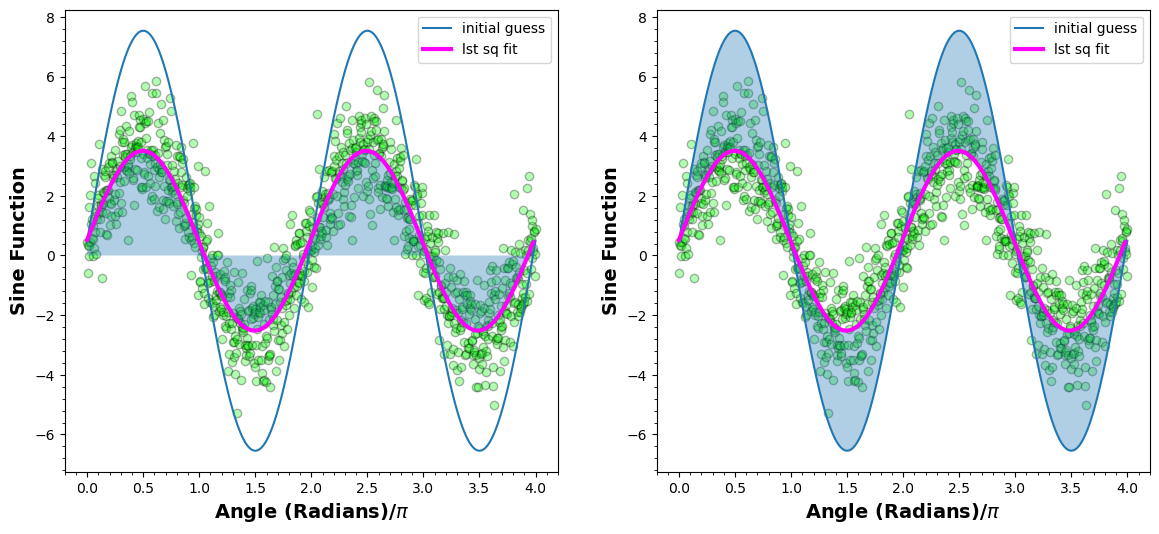

In [2]:
from scipy.optimize import leastsq
from matplotlib.ticker import AutoMinorLocator


N=1000 #number of data points
t=np.linspace(0,4*np.pi,N)
data=3*np.sin(t+0.001)+0.5+np.random.randn(N)
guess_mean=np.mean(data)
guess_std=3*np.std(data)
guess_phase =0
guess_freq=1
guess_amp=1

#purposefully set the initial guess to have an amplitude that is 2x too large
data_first_guess = guess_std*np.sin(t+guess_phase) + guess_mean
optimize_func = lambda x: x[0]*np.sin(x[1]*t+x[2]) + x[3] - data
est_amp, est_freq, est_phase, est_mean = leastsq(optimize_func, [guess_amp, guess_freq, guess_phase, guess_mean])[0]
#data_fit = est_amp*np.sin(est_freq*t+est_phase) + est_mean

#finer x-array sampling
fine_t = np.arange(0,max(t),0.1)

#data_first_guess_fine = guess_std*np.sin(fine_t+guess_phase) + guess_mean
data_fit_fine=est_amp*np.sin(est_freq*fine_t+est_phase)+est_mean

data_fit=est_amp*np.sin(est_freq*fine_t+est_phase)+est_mean
data_first_guess_fine=guess_std*np.sin(fine_t+guess_phase)+guess_mean

#toofine_t=np.arange(0,max(t),0.01)
#toodata_first_guess_fine=guess_std*np.sin(toofine_t+guess_phase) + guess_mean


fig,axes=plt.subplots(1,2,figsize=(14,6))

tp=t/np.pi
axes[0].scatter(tp,data,color='lime',alpha=0.3,edgecolor='black')
axes[0].plot(tp,data_first_guess,label='initial guess')
axes[0].plot(fine_t/np.pi,data_fit_fine,label='lst sq fit',color='magenta',linewidth=3)
axes[0].fill_between(fine_t/np.pi,data_fit,alpha=0.35)
axes[0].set_ylabel('Sine Function',size=14,weight='bold')
axes[0].set_xlabel(r'Angle (Radians)/$\pi$',size=14,weight='bold')
axes[0].xaxis.set_minor_locator(AutoMinorLocator(5))
axes[0].yaxis.set_minor_locator(AutoMinorLocator(5))

axes[0].legend(loc='best')


axes[1].scatter(tp,data,color='lime',alpha=0.3,edgecolor='black')
axes[1].plot(tp,data_first_guess,label='initial guess')
axes[1].plot(fine_t/np.pi,data_fit_fine,label='lst sq fit',color='magenta',linewidth=3)
#axes[1].fill_between(fine_t/np.pi,data_fit_fine,y2=toodata_first_guess_fine,alpha=0.35) #this does not work b/c y and y2 have diff lens
axes[1].fill_between(fine_t/np.pi,data_fit_fine,y2=data_first_guess_fine,alpha=0.35)
axes[1].set_ylabel('Sine Function',size=14,weight='bold')
axes[1].set_xlabel(r'Angle (Radians)/$\pi$',size=14,weight='bold')
axes[1].xaxis.set_minor_locator(AutoMinorLocator(5))
axes[1].yaxis.set_minor_locator(AutoMinorLocator(5))

axes[1].legend(loc='best')

plt.show()

Shaded regions are often used to identify confidence intervals and other similar statistical quantities.  In the example below, we use _fill\_between_ to plot the `variance of the predicted response'.   


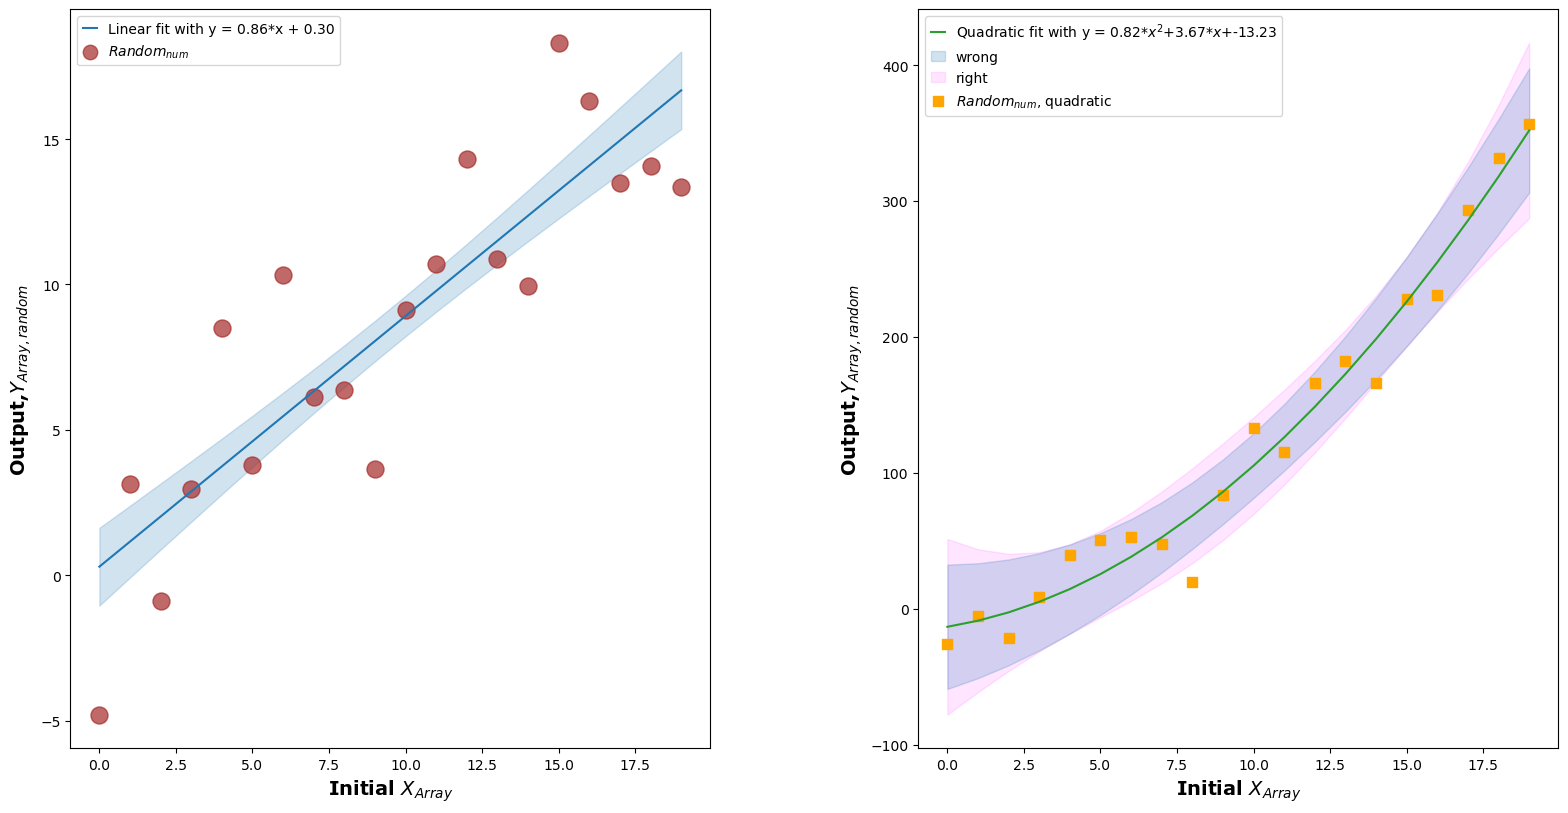

In [3]:
xarray=np.arange(20)   #an array of numbers from 0 to 19
yarray=np.arange(20)+3*np.random.randn(20)
#y is same as x EXCEPT now we vary the value +/- some random number about x

a,b=np.polyfit(xarray,yarray,1)
#a polynomial fit of degree one look up the documentation if you are curious

y_est=xarray*a+b

#'standard error of the predicted mean response' for simple linear model:
#https://en.wikipedia.org/wiki/Simple_linear_regression#Variance_of_the_mean_response
#i.e. if we observe infinitely many y's at a given x, what is the mean and how uncertain are we about the mean?

#ddof=2 accounts for slope & intercept (a,b) removing 2 deg of freedom
y_err=(yarray-y_est).std(ddof=2)*np.sqrt(1/len(xarray) + (xarray-xarray.mean())**2/np.sum((xarray-xarray.mean())**2))

yarray2=(np.arange(20))**2.+20*np.random.randn(20)

#polynomial of degree two
a2,b2,c2=np.polyfit(xarray,yarray2,2)

poly=np.poly1d(np.polyfit(xarray,yarray2,2))

#5times SE of predicted response
###Note###:
#technically, this isn't right: we are applying a SE of predicted response appropriate for linear regression to a quadratic!
y_err2=5*(yarray2-poly(xarray)).std(ddof=3)*np.sqrt(1/len(xarray) + (xarray-xarray.mean())**2/np.sum((xarray-xarray.mean())**2))

#####this is right####
# Design matrix (Vandermonde matrix)
bigX = np.vander(xarray, 3)  # [x², x, 1] for each point
# Residual standard error
residuals = yarray2 - poly(xarray)
s_e = np.sqrt(np.sum(residuals**2) / (len(xarray) - 3))
# Hat matrix diagonal (leverage)
H = bigX @ np.linalg.inv(bigX.T @ bigX) @ bigX.T
#or 
#H = np.dot(bigX, np.linalg.inv(np.transpose(bigX).dot(bigX)).dot(np.transpose(bigX)))
h_ii = np.diag(H)
# Standard error of fitted values
y_err2corr = 5*s_e * np.sqrt(h_ii)
#y_err2corr=5*(yarray2-poly(xarray)).std(ddof=3)*np.sqrt(1/len(xarray) + (xarray-xarray.mean())**2/np.sum((xarray-xarray.mean())**2))

sscale=2
fig,axes=plt.subplots(1,2,figsize=(9.6*sscale,4.8*sscale))
#thedefault width is 6.4 inches by 4.8 inches, here increase width by 50%

fig.subplots_adjust(wspace=0.325)
axes[0].plot(xarray,xarray*a+b,label='Linear fit with y = {0:.2f}*x + {1:.2f}'.format(a,b))

axes[0].fill_between(xarray,y_est-y_err,y_est+y_err,alpha=0.2,color='tab:blue')
axes[0].scatter(xarray,yarray,marker='o',s=150,alpha=0.7,label=r'$Random_{num}$',color='brown')
axes[0].legend(loc='upper left',fontsize='medium',handlelength=1,markerscale=0.85)

axes[1].plot(xarray,poly(xarray),c='tab:green',
             label=r'Quadratic fit with y = {0:.2f}*$x^2$+{1:.2f}*$x$+{2:.2f}'.format(a2,b2,c2),zorder=99)

axes[1].fill_between(xarray,poly(xarray)-y_err2,poly(xarray)+y_err2,alpha=0.2,label='wrong',zorder=90,color='tab:blue')
axes[1].fill_between(xarray,poly(xarray)-y_err2corr,poly(xarray)+y_err2corr,alpha=0.1,label='right',color='magenta',zorder=9)

axes[1].scatter(xarray,yarray2,marker='s',c='orange',s=50, label=r'$Random_{num}$, quadratic',zorder=91)
axes[1].legend(loc='upper left',fontsize='medium',handlelength=1)

for i in range(len(axes)):

 axes[i].set_xlabel('Initial $X_{Array}$',font='Verdana',size=14,color='black',weight='bold')
 axes[i].set_ylabel(r'Output,$Y_{Array, random}$',font='Verdana',size=14,color='black',weight='bold')

### Histogram Plots

Switching gears (substantially!) now ... a _**histogram**_ plot represents data provided in the form of some groups. It is an accurate method for the graphical representation of numerical data distribution. It is a type of bar plot where the X-axis represents the bin ranges while the Y-axis gives information about frequency.  A simple call looks like ``plt.hist(data,bins=number-of-bins,density=True/False,weights=weights,stacked=True/False`` or ``axes.hist(data,bins=number-of-bins,density=True/False,weights=weights,stacked=True/False`` using the axes container.  

Here's an example of a simple histogram plot

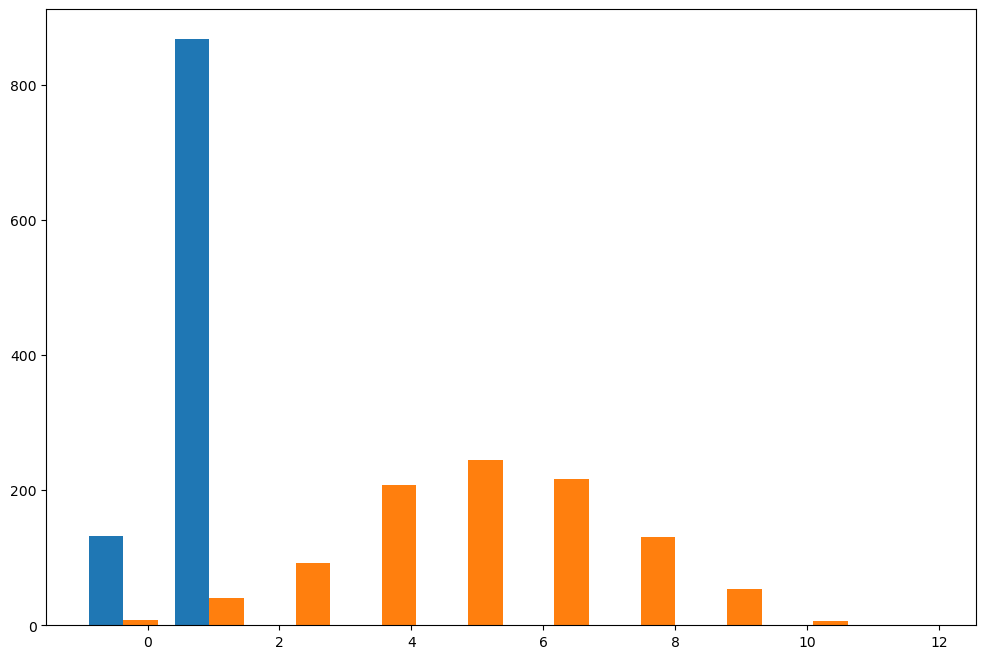

In [4]:
mu,sigma=0.5,0.2
yarray=np.arange(1000)
dataval=np.random.normal(mu,sigma,len(yarray))
plt.hist([dataval,10*dataval]);
#plt.hist(dataval)

Key parameters include

- 1) _bins_ - this is simply the number of bins. The default is 10.  Now, you can set a bin width by taking the full range of your data and dividing by some widthsize.  E.g. if x goes from 7 to 10 and you want the bin widths to be 0.1, then you can set ``nbins= (10-7)/0.1`` (i.e. 30 bins).
- 2) _stacked_ - If true, multiple data are stacked on top of each other; otherwise, different data are arranged side-by-side.
- 3) _density_ - If set to true, this will return a probability density.  each bin will display the bin's raw count divided by the total number of counts and the bin width (density = counts / (sum(counts) * np.diff(bins))), so that the area under the histogram integrates to 1 (np.sum(density * np.diff(bins)) == 1).
- 4) _histype_ - Can be bar, barstacked (data stacked on top of each other), step (line plot that is unfilled), and stepfilled (line plot that is filled).

Note that if you treat _hist_ as a function, it returns a tuple which is the number of points in each bin, the edge of the bins, and patches (container of individual 'artists' used to create the histogram): e.g. ``number,bins,patches=ax.hist(keywords)``.


The full API is here [https://matplotlib.org/stable/api/_as\_gen/matplotlib.pyplot.hist.html]().

Below, we redisplay the same plot as above but with more tunings

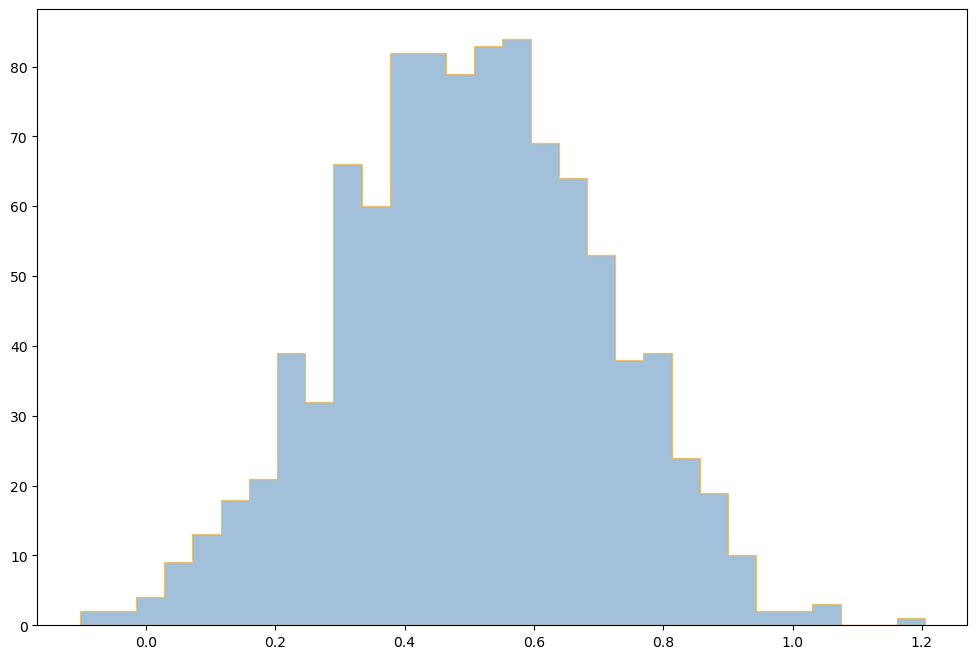

In [5]:
plt.hist(dataval, bins=30, density=False, alpha=0.5,
         histtype='stepfilled', color='steelblue',
         edgecolor='orange');

plt.show()

Note that in the above, earlier versions of ``plt.hist`` asked you to set "normed = True" for a density plot.  This keyword has changed.

The plt.hist docstring has more information on other customization options available. You can combine different historgram plots together on the same plot.   Making each histogram appear visible can be controlled with "stepfilled" and "alpha".   Here's an example.

Text(0, 0.5, 'Values')

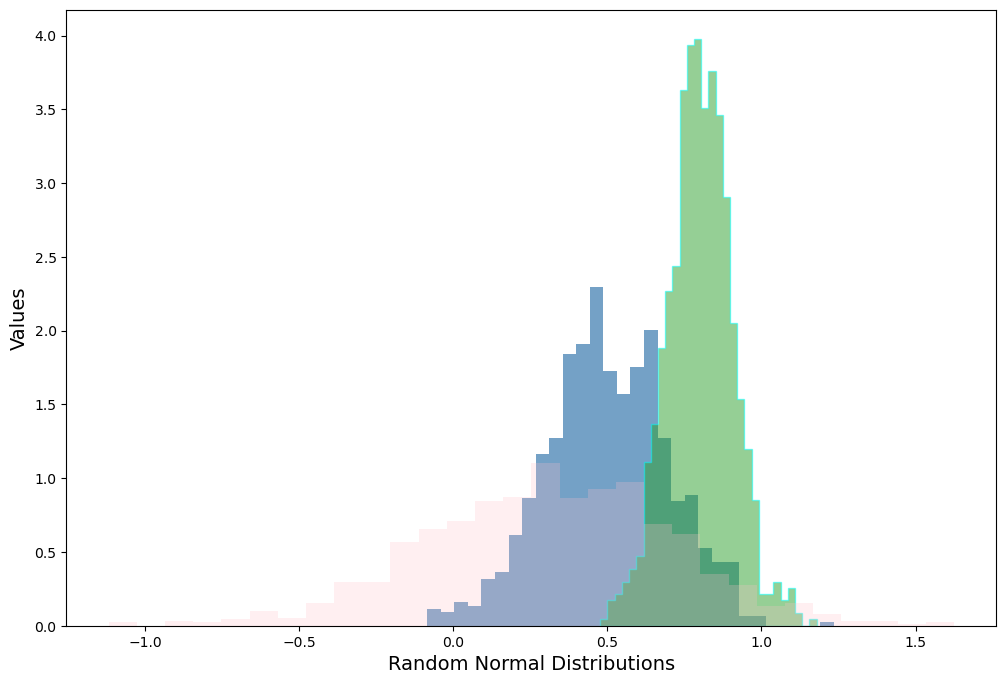

In [6]:

yarray=np.arange(1000)

mu,sigma=0.5,0.2
dataval=np.random.normal(mu,sigma,len(yarray))
mu2,sigma2=0.8,0.1
dataval2=np.random.normal(mu2,sigma2,len(yarray))
mu3,sigma3=0.3,0.4
dataval3=np.random.normal(mu3,sigma3,len(yarray))

plt.hist(dataval, bins=30, density=True, alpha=0.75,
         histtype='stepfilled', color='steelblue',
         edgecolor='none')
         
plt.hist(dataval2, bins=30, density=True, alpha=0.5,
         histtype='stepfilled', color='tab:green',
         edgecolor='cyan')
plt.hist(dataval3, bins=30, density=True, alpha=0.25,
         histtype='stepfilled', color='pink',
         edgecolor='none')
plt.xlabel('Random Normal Distributions',fontsize=14)
plt.ylabel('Values',fontsize=14)

Below is an example of a histogram plot of stellar ages drawn from a recent paper (Stanford-Moore and Nielsen 2017):

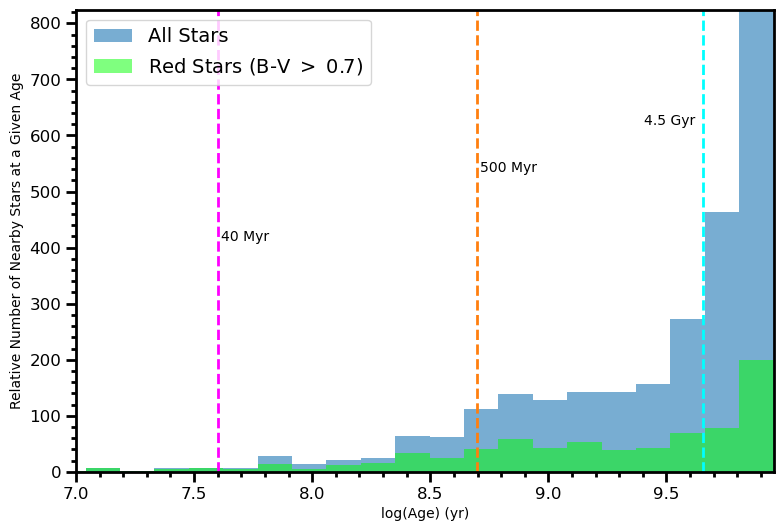

In [7]:
#import numpy as np
import math
import scipy
#import matplotlib.pyplot as plt

#this is "better way of doing importing stuff in most cases": we will get to this later, don't worry about it for now
from astropy.io import ascii

agefile='./files/table2cds.dat'

tab_sm=ascii.read(agefile)

names=tab_sm['ID']
median_age=np.log10(tab_sm['50AgeF']*1e6)

bmvcolor=tab_sm['B-V']

redstars=np.where(bmvcolor > 0.7)

#now make the figure

fig,ax=plt.subplots(1,1,figsize=(9,6))

#noweights needed
#weights=np.ones_like(median_age)/len(median_age)
ax.set_xlabel('log(Age) (yr)')
ax.set_ylabel('Relative Number of Nearby Stars at a Given Age')
ax.set_xlim(7,median_age.max())


#fordensity=True plot
#ax.set_ylim(0,1)

ax.tick_params(which='both',direction='out',width=2,labelsize='large')
ax.tick_params(which='major',length=7)
ax.tick_params(which='minor',length=3.5)
ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))
w=0.125
nbin=math.ceil((9.75-7)/w)
 
#sets the maximum equal to ~1 in this case for all histogram plot contributions
#ax.hist(median_age,bins=nbin,histtype='stepfilled',density='True',stacked='True',lw=3,alpha=0.6,label='All Stars')
#ax.hist(median_age[redstars],bins=nbin,histtype='stepfilled',density='True',stacked='True',lw=3,alpha=0.25,color='lime',label=r'Red Stars (B-V) $>$ 0.7')
 
#setsthe maximum to the actual maximum value in the bin
#n,bins,patches=ax.hist(median_age,bins=nbin,histtype='stepfilled',stacked='True',lw=3,alpha=0.6,label='All Stars')
 
#returnsa tuple to give you the number in each bin, number of bins, and patches.  Each element in patches is one bar in the histogram
n,bins,patches=ax.hist(median_age,bins=nbin,histtype='stepfilled'
                       ,lw=3,alpha=0.6,label='All Stars')


ax.hist(median_age[redstars],bins=nbin,histtype='stepfilled',
        lw=3,alpha=0.5,color='lime',label=r'Red Stars (B-V $>$ 0.7)')

#ax.hist( [median_age[redstars],median_age],bins=nbin,histtype='stepfilled',lw=5,alpha=0.6,stacked='False')
 
ax.set_ylim(0,n.max())

 
ax.axvline(x=np.log10(5e8),c='C1',linestyle='dashed',linewidth=2)
ax.axvline(x=np.log10(4e7),c='magenta',linestyle='dashed',lw=2)
ax.axvline(x=np.log10(4.5e9),c='cyan',linestyle='dashed',lw=2)
ax.text(np.log10(4.5e9)-.25,0.75*n.max(),'4.5 Gyr')
ax.text(np.log10(5e8)+0.01,0.65*n.max(),'500 Myr')
ax.text(np.log10(4e7)+0.01,0.5*n.max(),'40 Myr')
ax.legend(loc='upper left',fontsize=14)

plt.setp(ax.spines.values(),linewidth=2)

#or
#for axl in ['top','bottom','left','right']:
#   ax.spines[axl].set_linewidth(2)

plt.show()

The following demonstrates how 'stacked' works ...

Text(0.5, 1.0, 'Stacked')

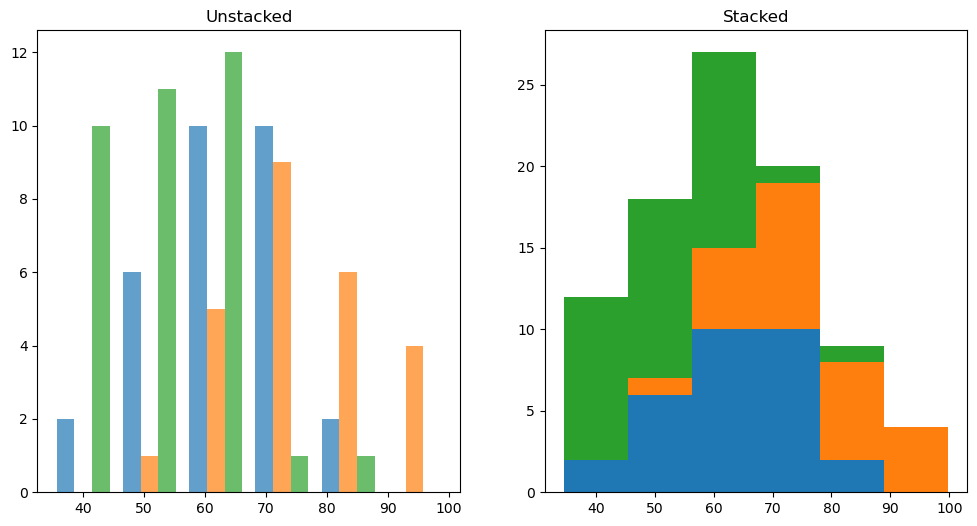

In [8]:
class1 = np.random.normal(65, 10, 30)
class2 = np.random.normal(75, 10, 25)
class3 = np.random.normal(55, 10, 35)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
# Unstacked - bars overlap
ax[0].hist([class1, class2, class3], bins=6,
label=['Class A', 'Class B', 'Class C'],
alpha=0.7, stacked=False)
ax[0].set_title('Unstacked')
# Stacked - bars stack on top
ax[1].hist([class1, class2, class3], bins=6,
label=['Class A', 'Class B', 'Class C'],
stacked=True)
ax[1].set_title('Stacked')

### 2-D Histograms

You can also do 2-D histogram plots using ``plt.hist2d`` (or ``ax.hist2d``), which accepts the _bins_ keyword and also accepts _cmin_ and _cmax_, which are minimum and maximum count values to display (values outside this range will be set to NaN).   Keywords can also adjust the color map and color scale: e.g. ``ax.hist2d(xdata,ydata,bins=10,cmap='Blues',norm=colors.LogNorm(vmin=vmin,vmax=vmax)``.

Below is a simple example ...

(-5.0, 5.0)

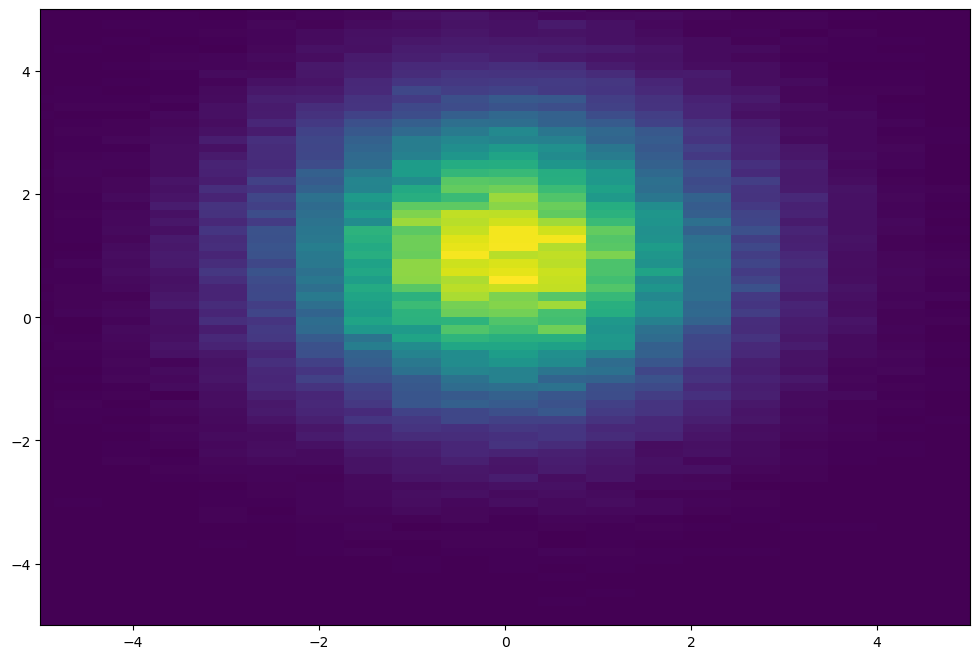

In [9]:
mean=[0,1]
stdev=[1.5,1.5]
samples1 = np.random.normal(loc=mean[0], scale=stdev[0], size=100000)
samples2 = np.random.normal(loc=mean[1], scale=stdev[1], size=100000)

#plt.hist2d(samples1,samples2,bins=50,cmap='jet');

fig,axes=plt.subplots()
axes.hist2d(samples1,samples2,bins=50,cmap='viridis');
#
from matplotlib import colors
#plt.hist2d(samples1,samples2,bins=50,cmap='jet',norm=colors.LogNorm());
#25 bins along x, 100 along y
axes.hist2d(samples1,samples2,bins=(25,100),cmap='viridis');

axes.set_xlim(-5,5)
axes.set_ylim(-5,5)

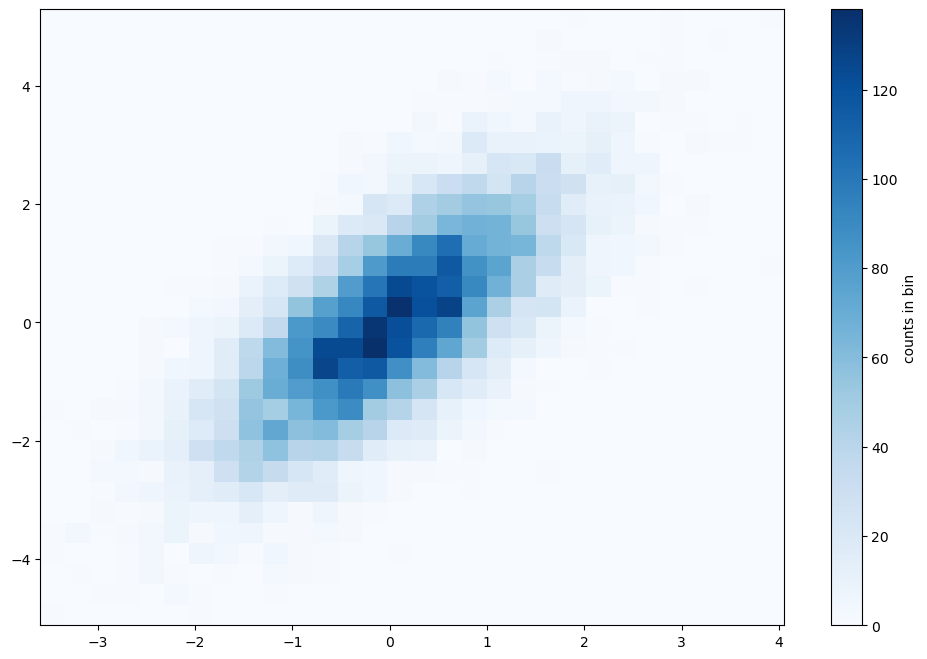

In [10]:
#slightly more complicated using a multivariate normal, which is a generalization
# of the 1Drandom.normal distribution to N dimensions ...

mean = [0, 0]
cov = [[1, 1], [1, 2]]
#cov = [[2, 2], [2, 2]]
#cov = [[1,2], [2,1]]
x, y = np.random.multivariate_normal(mean, cov, 10000).T
plt.hist2d(x, y, bins=30, cmap='Blues');   #note: the '#' disables the output print of the bins which gets ugly
#plt.xlim(-14,14)
#plt.ylim(-14,14)
cb = plt.colorbar()
cb.set_label('counts in bin')

#### Variations
We can do other kinds of markups for histogram(-like) plots.   

Here's one with hexogonal regions plotted instead of pixels



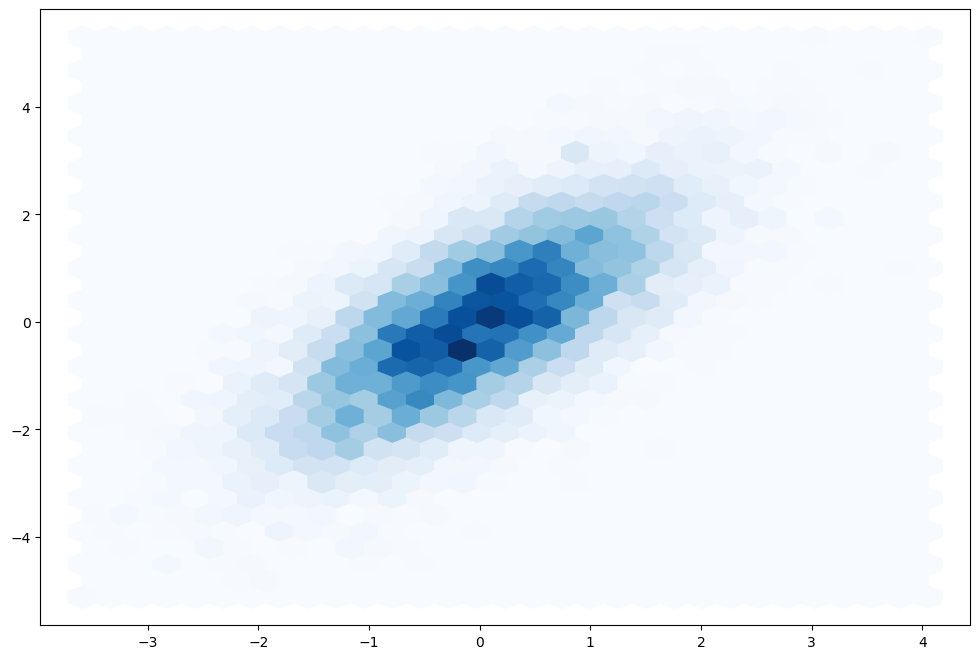

In [11]:
plt.hexbin(x, y, gridsize=30, cmap='Blues');

Another common method of evaluating densities in multiple dimensions is kernel density estimation (KDE).  KDE can be thought of as a way to "smear out" the points in space and add up the result to obtain a smooth function. One extremely quick and simple KDE implementation exists in the scipy.stats package. It includes a call to showing images (imshow) which we will get to later. Here is a quick example of using the KDE on this data:

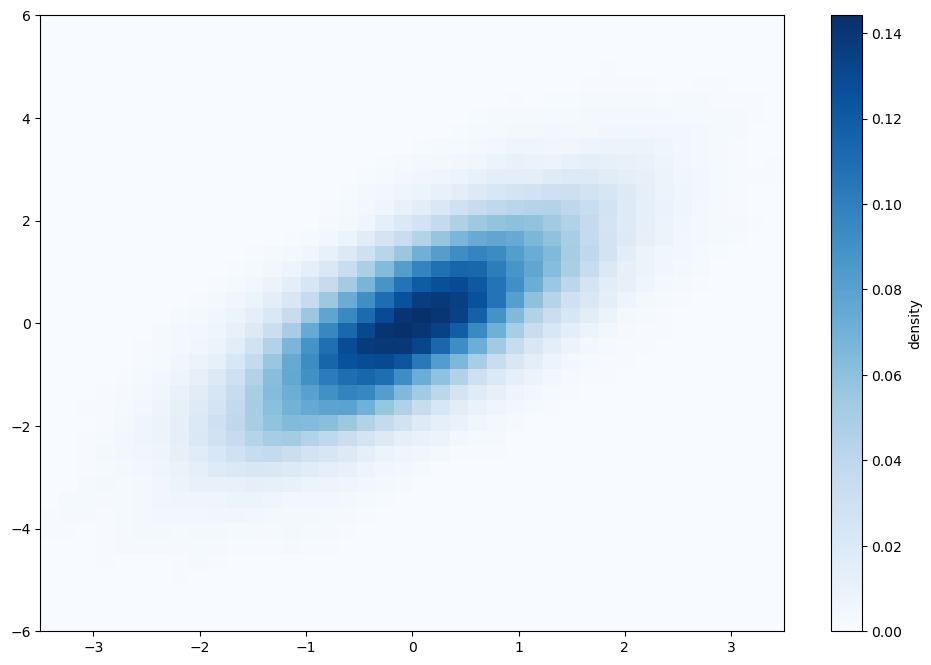

In [12]:
from scipy.stats import gaussian_kde

# fit an array of size [Ndim, Nsamples]
data = np.vstack([x, y])
kde = gaussian_kde(data)

# evaluate on a regular grid
xgrid = np.linspace(-3.5, 3.5, 40)
ygrid = np.linspace(-6, 6, 40)
Xgrid, Ygrid = np.meshgrid(xgrid, ygrid)
Z = kde.evaluate(np.vstack([Xgrid.ravel(), Ygrid.ravel()]))

# Plot the result as an image
plt.imshow(Z.reshape(Xgrid.shape),
           origin='lower', aspect='auto',
           extent=[-3.5, 3.5, -6, 6],
           cmap='Blues');
cb = plt.colorbar()
cb.set_label("density")

#### Colorbars with Histograms

Below is another hist-2d example with a colorbar added to map between color and number in each bin:

In [13]:
### (Ex_3.4)

#note: I'm writing this as a function now and then executing in the next cell
def ex3_4():
 import matplotlib.pyplot as plt
 import numpy as np
 from matplotlib.ticker import AutoMinorLocator

 x=np.random.normal(size=10000)
 y=x*3 + np.random.normal(size=10000)-1.5*np.random.randn(10000)

 fig,axes=plt.subplots()

 hist_2d=axes.hist2d(x,y,bins=(25,25))

 axes.set_xlabel('X Variable')
 axes.set_ylabel('Y Variable')
 axes.xaxis.set_minor_locator(AutoMinorLocator(5))
 axes.yaxis.set_minor_locator(AutoMinorLocator(5))
 #adding a color bar
 fig.colorbar(hist_2d[3],ax=axes,label='Counts')
 plt.show()



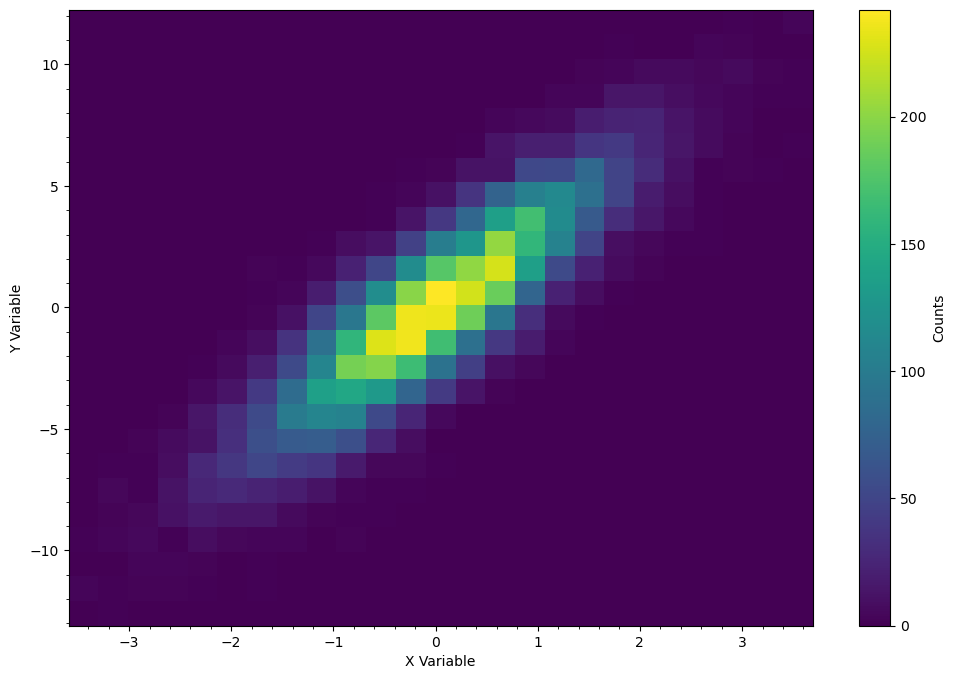

In [14]:
ex3_4()

It takes a bit of configuring, but you can also add horizontal and vertical histograms to a scatter plot or hist-2d plot.  The official documentation lists a couple of ways to do this: arguably the easiest is to not use ``plt.subplots()`` but use ``fig.add_gridspec`` to define a 2 by 2 grid but only fill 3 of the 4 spaces.  

Below is an example from the previous plot:

In [15]:
###(Ex_3.5)

def ex3_5():
    
 import matplotlib.pyplot as plt
 import numpy as np
 from matplotlib.ticker import AutoMinorLocator

 x=np.random.normal(size=10000)
 y=x*3 + np.random.normal(size=10000)-1.5*np.random.randn(10000)

 sscale=2
 fig=plt.figure(figsize=(7*sscale,7*sscale))
 gs=fig.add_gridspec(2,2,width_ratios=(4,1),height_ratios=(1,4),left=0.1,right=0.9,bottom=0.1,top=0.9,wspace=0.05,hspace=0.05)

 #first row, zeroth column
 axes=fig.add_subplot(gs[1,0])
 #zeroth row, zeroeth column
 ax_histx=fig.add_subplot(gs[0,0],sharex=axes)
    
     #first row, first column
 ax_histy=fig.add_subplot(gs[1,1],sharey=axes)

 hist_2d=axes.hist2d(x,y,bins=(25,25))

 axes.set_xlabel('X Variable')
 axes.set_ylabel('Y Variable')
 axes.xaxis.set_minor_locator(AutoMinorLocator(5))
 axes.yaxis.set_minor_locator(AutoMinorLocator(5))
 axes.tick_params(labeltop=True)

 ax_histx.hist(x,bins=25)
#now, re-set the ticks
 ax_histx.xaxis.set_ticks_position('top')
 ax_histx.xaxis.set_label_position('top')
 ax_histx.xaxis.set_minor_locator(AutoMinorLocator(5))
 ax_histx.yaxis.set_minor_locator(AutoMinorLocator(5))
 ax_histx.set_ylabel('Number')
 ax_histx.set_xlabel('X Variable')


 ax_histy.hist(y,bins=25,orientation='horizontal')
 ax_histy.xaxis.set_ticks_position('top')
 ax_histy.xaxis.set_label_position('top')
 ax_histy.yaxis.set_ticks_position('right')
 ax_histy.yaxis.set_label_position('right')
 ax_histy.xaxis.set_minor_locator(AutoMinorLocator(5))
 ax_histy.yaxis.set_minor_locator(AutoMinorLocator(5))
 ax_histy.set_xlabel('Number')
 ax_histy.set_ylabel('Y Variable',rotation=270)




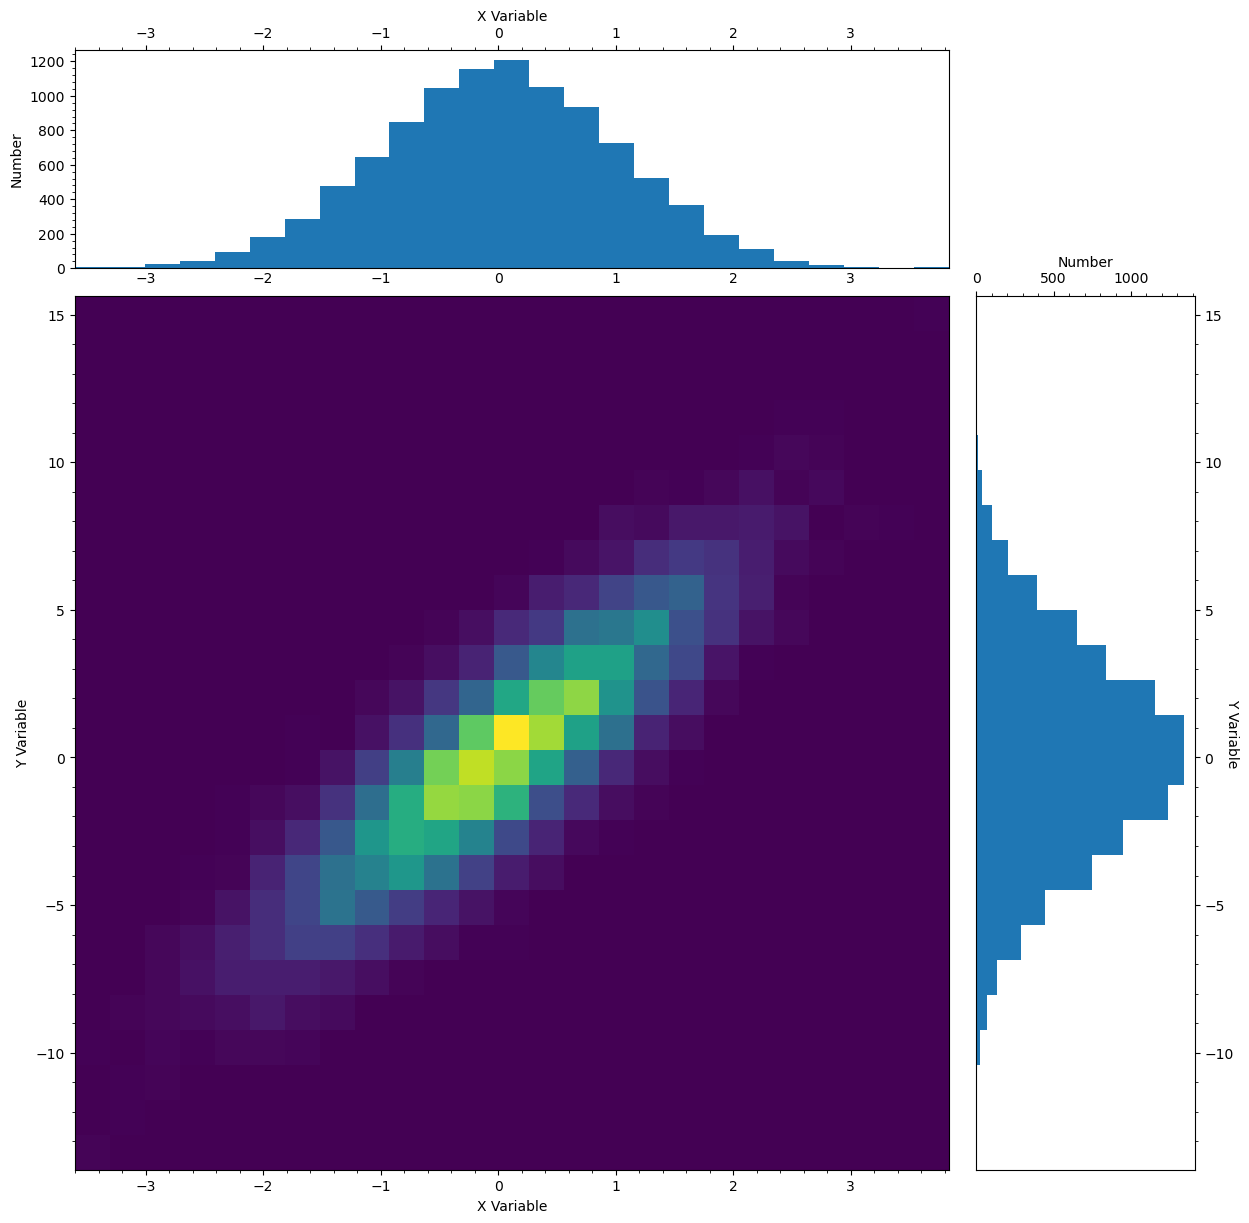

In [16]:
ex3_5()

### Contour Plots

For a parameter Z which is a function of coordindates x and y (Z = f(x,y)), a contour plot represents a 3-dimensional surface by plotting constant z values (i.e. called contours) on a 2-dimensional format (x and y).  Common uses for contour plots include a distribution of chi-squared values as a function of two variables or intensity contours for images.  

The main matplotlib function for contour plots is, naturally, _**plt.contour()**_, or _**plt.contourf()**_ for a _filled_ contour. The API for the main contour plot function is here: [https://matplotlib.org/stable/api/_as\_gen/matplotlib.pyplot.contour.html]().   The API for the filled contour plot is here: [https://matplotlib.org/stable/api/_as\_gen/matplotlib.pyplot.contourf.html]().  

The official _matplotlib_ documentation and a lot of easily accessible examples show contour plots that are pretty simple (just f(x,y) = sqrt(x^2+y^2)) and not so representative of how you would actually use this function.   Here's a more complex version from the _Scientific Computing With Python_ book.

In [17]:
##(Ex_3.6)

def ex3_6():

#From Scientific Computing With Python

 #import matplotlib.pyplot as plt
 #import numpy as np
 #from matplotlib.ticker import AutoMinorLocator

 rosenbrockfunction= lambda x,y: (1-x)**2+100*(y-x**2)**2
 X,Y=np.meshgrid(np.linspace(-0.5,2,100),np.linspace(-1,4,100))
 Z=rosenbrockfunction(X,Y)
 
 sscale=2
 fig,axes=plt.subplots(figsize=(7*sscale,7*sscale))

 axes.set_xlabel('X Variable')
 axes.set_ylabel('Y Variable')
 axes.xaxis.set_minor_locator(AutoMinorLocator(5))
 axes.yaxis.set_minor_locator(AutoMinorLocator(5))

 contour=axes.contour(X,Y,Z,np.logspace(-0.5,3.5,20,base=10),cmap='rainbow')
 axes.clabel(contour,contour.levels[1:],inline=True,fontsize=10,colors='black')


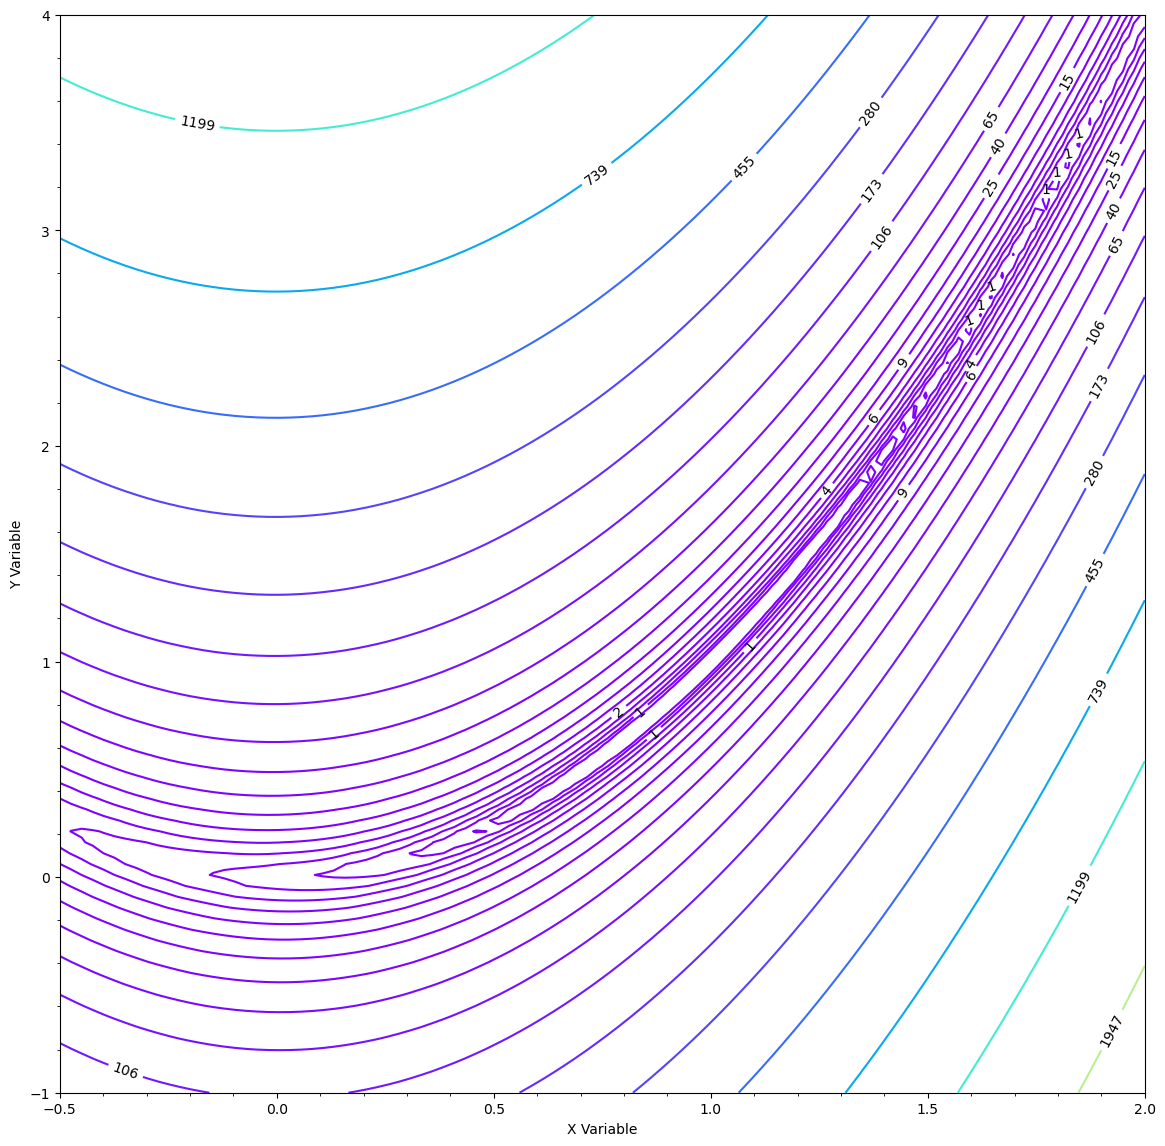

In [18]:
ex3_6()

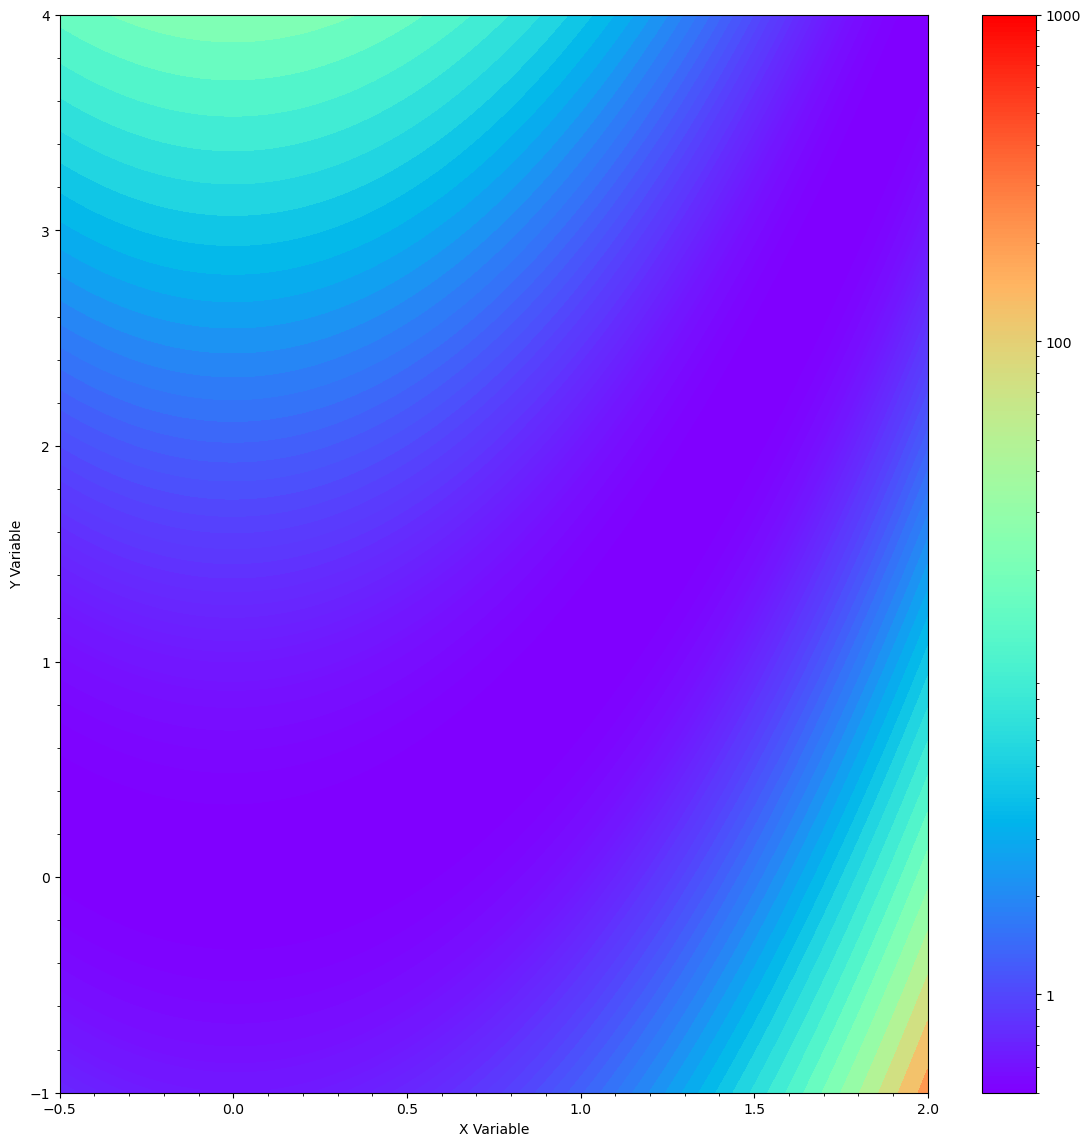

In [19]:
#From Scientific Computing With Python

#now we go back to without a def call
 #import matplotlib.pyplot as plt
 #import numpy as np
 #from matplotlib.ticker import AutoMinorLocator
from matplotlib import colors

rosenbrockfunction= lambda x,y: (1-x)**2+100*(y-x**2)**2+0.5 #added tiny bit to make sure colors displayed
X,Y=np.meshgrid(np.linspace(-.5,2,100),np.linspace(-1,4,100))
 #X,Y=np.meshgrid(np.linspace(-0.5,2,100),np.linspace(-1,4,100))
Z=rosenbrockfunction(X,Y)
sscale=2
fig,axes=plt.subplots(figsize=(7*sscale,7*sscale))

axes.set_xlabel('X Variable')
axes.set_ylabel('Y Variable')
axes.xaxis.set_minor_locator(AutoMinorLocator(5))
axes.yaxis.set_minor_locator(AutoMinorLocator(5))

contour=axes.contourf(X,Y,Z,np.logspace(-0.5,3.5,100,base=10),cmap='rainbow')
 #axes.clabel(contour,contour.levels[1:],inline=True,fontsize=10,colors='black')

norm=colors.LogNorm(contour.cvalues.min(),contour.cvalues.max())
sm=plt.cm.ScalarMappable(cmap='rainbow',norm=norm)
sm.set_clim(vmin=0.5,vmax=1000)
 #sm.set_array([])
fig.colorbar(sm,ticks=(1,100,1000),ax=plt.gca(),cmap='rainbow',format='%d')


**Major Caveat** - The above code pieces and usage of contour plots assumes that you have data on a **regularly-spaced grid**: i.e. a grid of x and y, where the separation between neighboring grid points is constant and where there are values f(x,y) at every point.   This is not always the case: in fact, in many cases, you have _irregularly-spaced_ x and y points (e.g. a grid of chi^2 values for some fit to a star's spectrum for different temperatures and gravities).

When you have _irregularly-spaced_ grid points, you need to use a different function: ``axes.tricontour`` and ``axes.tricontourf``.   These functions draw contour lines on an unstructured triangular grid.  To make the contour plots appear correctly, you need a triangulation function: e.g. ``matplotlib.tri.Triangulation(x,y)`` (i.e. create a triangular grid for the exiting (irregularly-spaced) grid).  

An example:

```
import matplotlib as mpl
contour_plot_irregular=axes.tricontour(mpl.tri.Triangulation(x,y),z,
   levels=levels,linewidths=linewidths, colors=colors)
```


, where levels, linewidths, and colors are set before in the code, x and y are the irregular grid points, and z is the value z=f(x,y).

The APIs for the relevant functions are here:

[https://matplotlib.org/stable/api/_as\_gen/matplotlib.axes.Axes.tricontour.html]()
[https://matplotlib.org/stable/api/_as\_gen/matplotlib.axes.Axes.tricontour.html]()
[https://matplotlib.org/stable/api/tri_api.html#matplotlib.tri.Triangulation]()

Below is one example where I produce a contour plot in $\chi^{2}$ for an atmosphere model grid with a range of values for temperature and surface gravity.

In [20]:
import matplotlib as mpl

def run(title='HIP 99770 b'):
    
#def run(indir='btsettl_fit_cloudy',title='HIP 99770 b'):

    infile='fitoutcomeresults.txt'

    #data types for the columns
    dtypes={'names':('fname','temp','logg','sqrtalphaout','chisq','reduced_chisq'),'formats':(str,np.float64,np.float64,np.float64,np.float64,np.float64)}
    
    #data=np.loadtxt('./'+indir+'/'+infile,usecols=range(6),dtype=dtypes)
    data=np.loadtxt('./sect3/files/'+infile,usecols=range(6),dtype=dtypes)
    fname=data['fname']
    temperature = data['temp']
    surface_gravity = data['logg']
    chisq = data['chisq']
    reduced_chisq = data['reduced_chisq']
    delta_chi = chisq - np.min(chisq)

    x= temperature
    y=surface_gravity
    zz=chisq
    z=zz-np.min(zz) #delta_chi

    bestfit=np.argmin(zz)
    fig,ax=plt.subplots()

    #3 and 5 sigma confidence levels
    delta_confidence_levels = np.array([11.8,28.744])
    #delta_confidence_levels = np.array([2.3,6.17,11.8])

    levels = np.min(delta_chi) + delta_confidence_levels

    contour=ax.tricontour(mpl.tri.Triangulation(x,y),z,levels=levels,
                            linewidths=0.75, colors = ['magenta','blue','purple'])

    contourf=ax.tricontourf(mpl.tri.Triangulation(x,y),z,levels=10,
                            linewidths=0.75, cmap='cividis_r')
                            #linewidths=0.75, cmap='cividis_r')

    fmt = {}
    strs = [r'$3\sigma$',r'$5\sigma$']
    #strs = [r'1$\sigma$',r'$2\sigma$', r'$3\sigma$']
    for l, s in zip(contour.levels, strs):
        fmt[l]=s

    ax.plot(x[bestfit],y[bestfit],'rD')

    ax.clabel(contour, contour.levels, inline=True, fmt=fmt, fontsize=10)

    #ax.set(xlim=(np.min(x),np.max(x)),ylim=(np.min(y),np.max(y)))
    ax.set_xlim(np.min(x),np.max(x))
    ax.set_ylim(3,5)
    ax.set_title(title)
    ax.set_xlabel('$T_{eff}$ (K)')
    ax.set_ylabel('log(g)')
    plt.show()

/var/folders/jd/2nq0dfy94lsddczv0kg2y33h0000gn/T/ipykernel_72317/2699364309.py:38: UserWarning: linewidths is ignored by contourf
  contourf=ax.tricontourf(mpl.tri.Triangulation(x,y),z,levels=10,


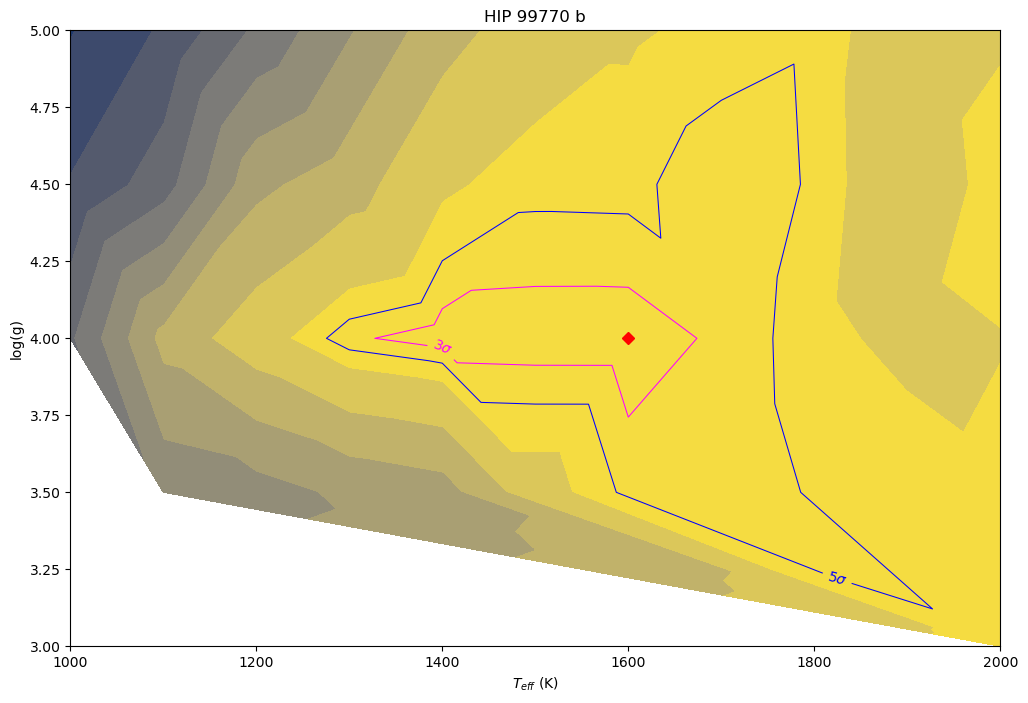

In [21]:
run()